Ген CD14       | Корреляция с псевдовременем: r = -0.025 | p = 3.99e-04
Ген FCGR3A     | Корреляция с псевдовременем: r =  0.037 | p = 1.76e-07
Ген CX3CR1     | Корреляция с псевдовременем: r =  0.023 | p = 1.30e-03
Ген C1QA       | Корреляция с псевдовременем: r =  0.018 | p = 1.24e-02


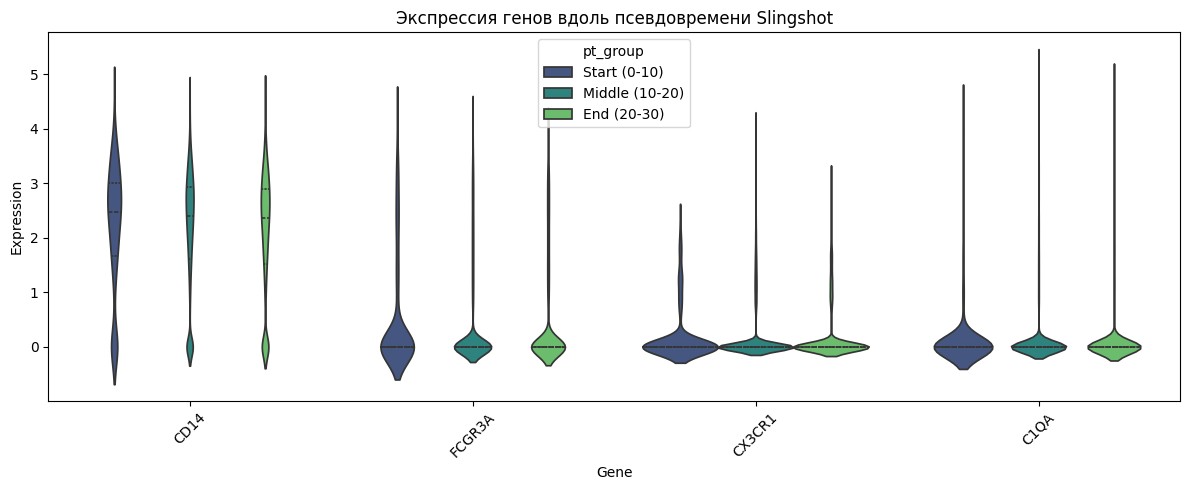

In [10]:
import pandas as pd
import numpy as np
import scanpy as sc
from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

adata_mono = sc.read_h5ad('../data_bio/covid_mono_only.h5ad')
df_pt = pd.read_csv('../data_bio/slingshot_pseudotime_20pc.csv')

adata_mono.obs['slingshot_pt'] = np.nan
adata_mono.obs.iloc[df_pt['cell_idx'].values, adata_mono.obs.columns.get_loc('slingshot_pt')] = df_pt['pseudotime'].values
adata_sub = adata_mono[~adata_mono.obs['slingshot_pt'].isna()].copy()

genes = ['CD14', 'FCGR3A', 'CX3CR1', 'C1QA']
valid_genes = [g for g in genes if g in adata_sub.var_names]

for gene in valid_genes:
    expr = adata_sub[:, gene].X.toarray().flatten()
    corr, pval = spearmanr(adata_sub.obs['slingshot_pt'], expr)
    print(f"Ген {gene:10s} | Корреляция с псевдовременем: r = {corr:6.3f} | p = {pval:.2e}")

bins = [0, 10, 20, 30] 
labels = ['Start (0-10)', 'Middle (10-20)', 'End (20-30)']
adata_sub.obs['pt_group'] = pd.cut(adata_sub.obs['slingshot_pt'], bins=bins, labels=labels, include_lowest=True)

df_plot = pd.DataFrame(adata_sub[:, valid_genes].X.toarray(), columns=valid_genes)
df_plot['pt_group'] = adata_sub.obs['pt_group'].values
df_melt = df_plot.melt(id_vars='pt_group', var_name='Gene', value_name='Expression')

plt.figure(figsize=(12, 5))
sns.violinplot(data=df_melt, x='Gene', y='Expression', hue='pt_group', split=False, inner="quart", palette="viridis")
plt.title("Экспрессия генов вдоль псевдовремени Slingshot")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

            Gene  Spearman_r         p_adj
1160      S100A8   -0.064672  4.835902e-16
6288      EEF1A1    0.056111  7.895405e-12
10020       FTH1    0.056030  7.895405e-12
6046    HLA-DPB1    0.049501  7.586310e-09
9979       MS4A7    0.047200  6.152905e-08
6045    HLA-DPA1    0.046556  9.626976e-08
3671   MTRNR2L12    0.045768  1.761429e-07
9657        CTSD   -0.045580  1.844410e-07
10572      HSPA8    0.045205  2.338636e-07
8313         CLU   -0.044324  4.795571e-07
1158      S100A9   -0.043000  1.430997e-06
6655     RNASET2    0.042925  1.430997e-06
10927       PSAP    0.042555  1.839164e-06
5529       CSF1R    0.041696  3.643584e-06
6026     HLA-DRA    0.041405  4.380554e-06
7640       AP1S2    0.041190  4.947486e-06
5534        CD74    0.041011  5.429767e-06
8617       RPL30    0.040552  7.594777e-06
15270       CD68    0.040149  1.011676e-05
1162      S100A6   -0.039940  1.146043e-05
2404    IGKV3-20   -0.039807  1.220099e-05
1159     S100A12   -0.039727  1.245059e-05
18976      

<positron-console-cell-11>:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



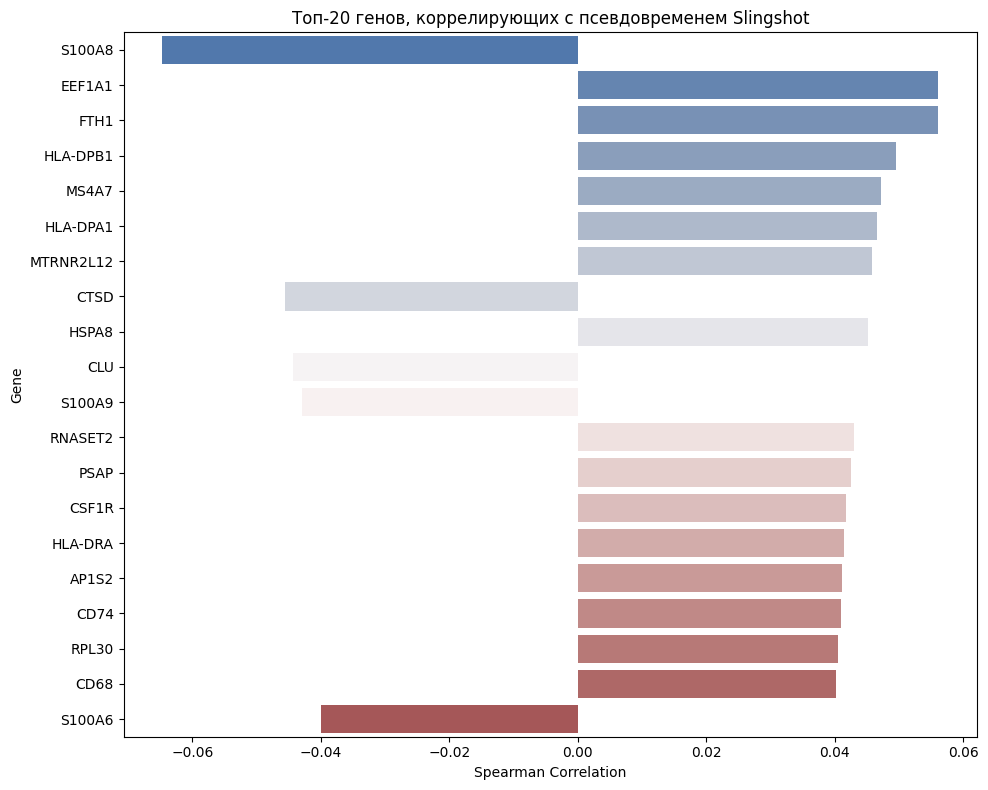

In [11]:
import pandas as pd
import numpy as np
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multitest import multipletests

adata_mono = sc.read_h5ad('../data_bio/covid_mono_only.h5ad')
df_pt = pd.read_csv('../data_bio/slingshot_pseudotime_20pc.csv')

adata_mono.obs['slingshot_pt'] = np.nan
adata_mono.obs.iloc[df_pt['cell_idx'].values, adata_mono.obs.columns.get_loc('slingshot_pt')] = df_pt['pseudotime'].values
adata_sub = adata_mono[~adata_mono.obs['slingshot_pt'].isna()].copy()

is_gene = adata_sub.var['feature_types'] == 'Gene Expression'
adata_genes = adata_sub[:, is_gene].copy()

X = adata_genes.X.toarray() if hasattr(adata_genes.X, 'toarray') else adata_genes.X
pt = adata_genes.obs['slingshot_pt'].values

results = []
for i, gene_name in enumerate(adata_genes.var_names):
    expr = X[:, i]
    
    if np.std(expr) == 0:
        continue
        
    corr, pval = spearmanr(pt, expr)
    results.append({'Gene': gene_name, 'Spearman_r': corr, 'p_value': pval})

df_res = pd.DataFrame(results)

df_res['p_adj'] = multipletests(df_res['p_value'], method='fdr_bh')[1]

df_res['abs_r'] = df_res['Spearman_r'].abs()
df_res = df_res.sort_values(by='abs_r', ascending=False)

top_genes = df_res.head(30)
print(top_genes[['Gene', 'Spearman_r', 'p_adj']])

plt.figure(figsize=(10, 8))
sns.barplot(data=top_genes.head(20), x='Spearman_r', y='Gene', palette='vlag')
plt.title('Топ-20 генов, коррелирующих с псевдовременем Slingshot')
plt.xlabel('Spearman Correlation')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()